<a href="https://colab.research.google.com/github/vishwa24816/Time-series-momentum/blob/main/Time_series_momentum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [34]:
# !pip install yfinance matplotlib -q
import numpy as np, pandas as pd, yfinance as yf
import matplotlib.pyplot as plt

In [35]:
tickers = ["SPY","QQQ","IWM","EFA","TLT","GLD"]   # US large, tech, small, intl, bonds, gold
end = pd.Timestamp.today()
start = end - pd.DateOffset(years=20)
px = yf.download(tickers, start=start, end=end, interval="1d",
                 auto_adjust=True, progress=False)["Close"].dropna()
print(px.shape, px.index[0].date(), "to", px.index[-1].date())

(5031, 6) 2006-10-31 to 2026-10-30


In [36]:
def build_weights(px, lookback=252, ma_len=200, cost_bps=5):
    n = px.shape[1]
    mom = px.pct_change(lookback)
    ma = px.rolling(ma_len).mean()
    on = ((mom > 0) & (px > ma)).astype(float)          # 1 if trend is up
    month_ends = px.groupby(px.index.to_period("M")).tail(1).index
    w_month = on.loc[month_ends] / n                     # 1/N per active asset, rest cash
    w_daily = w_month.reindex(px.index, method="ffill").shift(1).fillna(0)  # no lookahead
    gross = (px.pct_change().fillna(0) * w_daily).sum(axis=1)
    turnover = w_daily.diff().abs().sum(axis=1).fillna(0)
    net = gross - turnover * cost_bps / 10000
    return net, w_daily

net, w = build_weights(px)
spy = px["SPY"].pct_change().fillna(0)

In [37]:
def metrics(r, name):
    r = r.dropna()
    eq = (1 + r).cumprod()
    years = len(r) / 252
    cagr = eq.iloc[-1] ** (1 / years) - 1
    vol = r.std() * np.sqrt(252)
    sharpe = r.mean() * 252 / vol if vol > 0 else np.nan
    dd = (eq / eq.cummax() - 1).min()
    return pd.Series({"CAGR": cagr, "Volatility": vol, "Sharpe (rf=0)": sharpe,
                      "Max drawdown": dd, "Calmar": cagr / abs(dd)}, name=name)

summary = pd.DataFrame([metrics(net, "Trend strategy"), metrics(spy, "SPY buy & hold")])
display(summary.round(3))
print("Average invested fraction:", round(w.sum(axis=1).mean(), 3))

,CAGR,Volatility,Sharpe (rf=0),Max drawdown,Calmar
Trend strategy,0.062,0.081,0.781,-0.112,0.549
SPY buy & hold,0.109,0.195,0.630,-0.552,0.198


Average invested fraction: 0.573


In [38]:
mid = px.index[len(px) // 2]
for name, mask in [("In-sample", px.index < mid), ("Out-of-sample", px.index >= mid)]:
    s = net[mask]; b = spy[mask]
    print(f"--- {name} ---")
    display(pd.DataFrame([metrics(s, "Strategy"), metrics(b, "SPY")]).round(3))

--- In-sample ---


,CAGR,Volatility,Sharpe (rf=0),Max drawdown,Calmar
Strategy,0.045,0.077,0.612,-0.107,0.424
SPY,0.067,0.208,0.415,-0.552,0.121


--- Out-of-sample ---


,CAGR,Volatility,Sharpe (rf=0),Max drawdown,Calmar
Strategy,0.078,0.084,0.938,-0.112,0.697
SPY,0.153,0.180,0.883,-0.337,0.454


In [39]:
rows = []
for lb in [126, 252]:
    for ma in [100, 200]:
        for c in [0, 5, 10]:
            r, _ = build_weights(px, lookback=lb, ma_len=ma, cost_bps=c)
            m = metrics(r, "")
            rows.append({"lookback": lb, "ma": ma, "cost_bps": c,
                         "CAGR": m["CAGR"], "Sharpe": m["Sharpe (rf=0)"],
                         "MaxDD": m["Max drawdown"]})
grid = pd.DataFrame(rows).round(3)
grid

,lookback,ma,cost_bps,CAGR,Sharpe,MaxDD
0,126,100,0,0.052,0.695,-0.114
1,126,100,5,0.050,0.678,-0.115
2,126,100,10,0.049,0.660,-0.117
3,126,200,0,0.066,0.803,-0.112
4,126,200,5,0.065,0.793,-0.112
5,126,200,10,0.065,0.783,-0.113
6,252,100,0,0.051,0.716,-0.093
7,252,100,5,0.050,0.700,-0.093
8,252,100,10,0.049,0.683,-0.094
9,252,200,0,0.062,0.791,-0.112


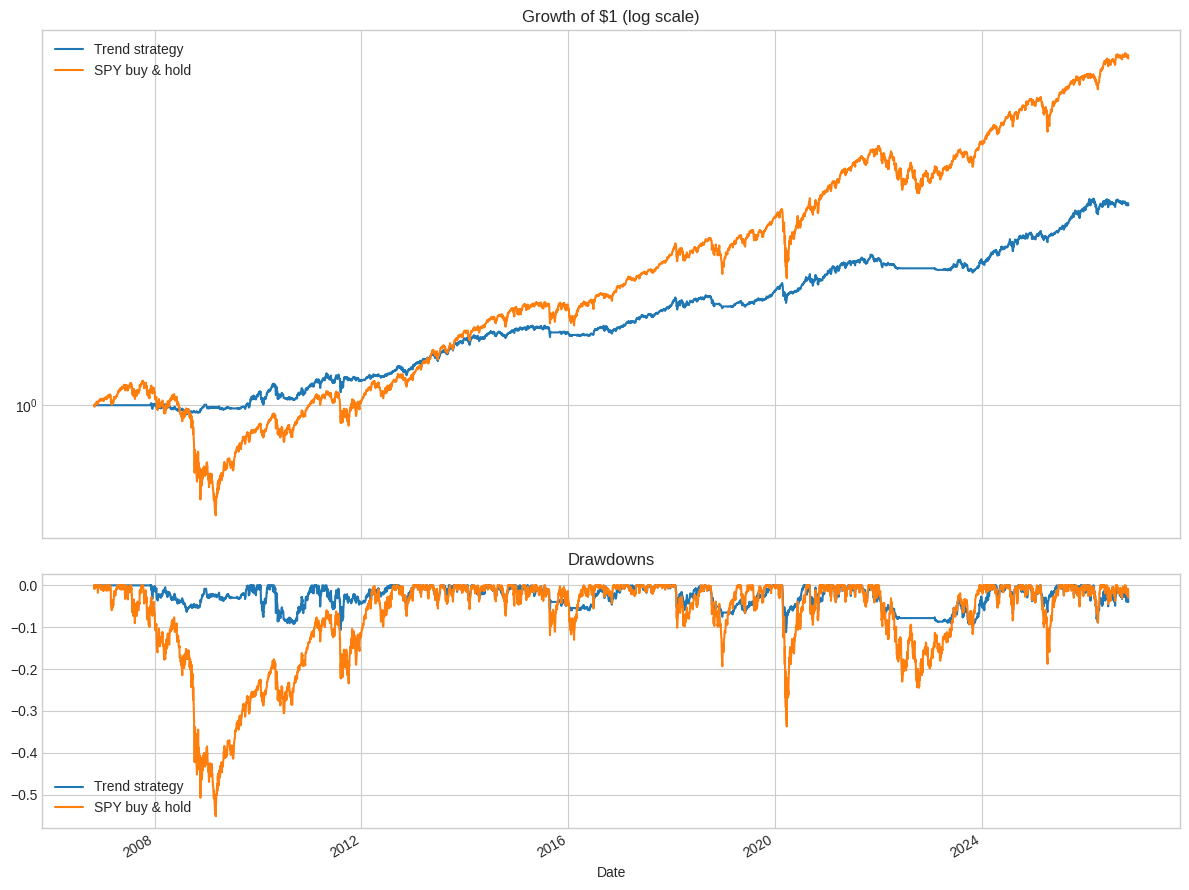

In [40]:
eq = pd.DataFrame({"Trend strategy": (1 + net).cumprod(),
                   "SPY buy & hold": (1 + spy).cumprod()})
fig, ax = plt.subplots(2, 1, figsize=(12, 9), sharex=True,
                       gridspec_kw={"height_ratios": [2, 1]})
eq.plot(ax=ax[0], logy=True, title="Growth of $1 (log scale)")
dd = eq / eq.cummax() - 1
dd.plot(ax=ax[1], title="Drawdowns")
plt.tight_layout(); plt.show()

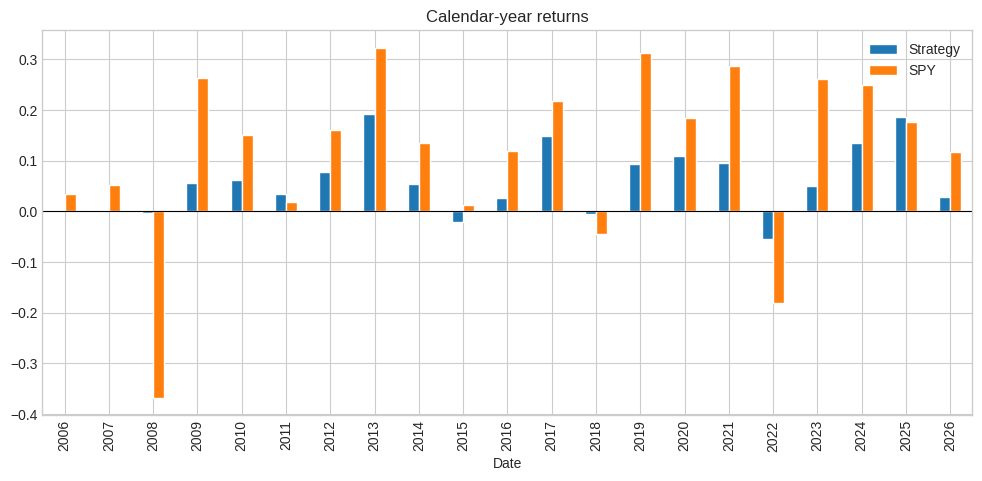

Years strategy beat SPY: 5 of 21


In [41]:
yr = pd.DataFrame({"Strategy": (1 + net).groupby(net.index.year).prod() - 1,
                   "SPY": (1 + spy).groupby(spy.index.year).prod() - 1})
yr.plot(kind="bar", figsize=(12, 5), title="Calendar-year returns")
plt.axhline(0, color="black", lw=0.8); plt.show()
print("Years strategy beat SPY:", (yr.Strategy > yr.SPY).sum(), "of", len(yr))

In [42]:
latest = w.iloc[-1]
print("Current allocation (fraction of capital):")
print(latest[latest > 0].round(3) if (latest > 0).any() else "All in cash")
print(f"Cash: {1 - latest.sum():.1%}")

Current allocation (fraction of capital):
Ticker
EFA    0.167
IWM    0.167
QQQ    0.167
SPY    0.167
Name: 2026-10-30 00:00:00, dtype: float64
Cash: 33.3%
